# Fig. 3: mismatch-repair mutants differ only in the spontaneous mutation rate

3b  the mutant-number CCDF for each of wildtype, msh6D and msh2D, at a range of
      population sizes, with the Luria-Delbruck distribution at the fitted mu
      overlaid.  All three follow the canonical form; only the rate differs.

  3d  the same data collapsed.  The Luria-Delbruck distribution depends on mu and N
      only through their product, so if the strains differ *only* in mu, rescaling N
      to give a common mu*N should superimpose them.  Each strain is binned at its own
      k = mu * totalN / (mu*N) to hit target products of 1, 5 and 25.  The collapse
      holds, which is the evidence that mismatch repair acts on mu alone -- any
      additional adaptive mechanism would have deformed the shape and broken it.

Both panels use the Laplace fit (SI section 5.5): mu from the cached fit parameters,
alpha from LAPLACE_ALPHA below.

Fig. 3b uses its own set of bin counts, chosen to span the population sizes worth
showing, rather than the set used for the S5 fit panels.  Runtime: ~2 min.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from barfly import expt2, ld                                            # noqa: E402
from barfly.plotting import (STRAIN_COLORMAPS, STRAIN_NAMES,
                               strain_bin_count_colour,
                               use_paper_style)                           # noqa: E402

OUTPUT_DIR = ROOT / "output"

# Laplace-fit alpha per strain.  The cached fit parameters carry the least-squares
# alpha and the Laplace mu, but no Laplace alpha, so these are stated explicitly.
LAPLACE_ALPHA = {"yKH88": 7.074, "yFR1": 3.798, "yFR2": 1.095}

BIN_COUNTS_3B = np.array([16000, 8000, 4000, 2000, 1000, 500])
TARGET_PRODUCTS = [1.0, 5.0, 25.0]
PRODUCT_LINESTYLE = {1.0: "-", 5.0: "--", 25.0: "-."}
N_REPLICATES_PLOT = 3_000_000
SEED = 20260907

In [2]:
def total_mutants_for(strain, counts_post, reads_post, plated_cfu, alpha):
    """Absolute mutant count implied by the reads and the plating calibration."""
    return (np.sum(counts_post[strain]) / reads_post[strain]) * plated_cfu[strain] * alpha

In [3]:
def plot_per_strain_ccdf(strains, counts_pre, counts_post, reads_post, plated_cfu,
                         total_n, best_mu, best_alpha):
    """3b: one panel per strain, data at several N with the fitted theory overlaid."""
    n_bin_counts = len(BIN_COUNTS_3B)
    _, axes = plt.subplots(1, 3, sharey=True, sharex=True, figsize=(13, 4))

    for axis, strain in zip(axes, strains):
        total_mutants = total_mutants_for(strain, counts_post, reads_post, plated_cfu,
                                          best_alpha[strain])
        largest_observed = 1.0
        for i_k, n_bins in enumerate(BIN_COUNTS_3B):
            _, _, binned_post = ld.bin_barcodes(counts_pre[strain],
                                                counts_post[strain], n_bins)
            observed = np.sort(total_mutants * binned_post / np.sum(binned_post))
            largest_observed = max(largest_observed, observed[-1])

            # log-spaced up to the fifth largest, then each jackpot individually
            thresholds = np.concatenate([
                np.logspace(0, np.log10(observed[-5]), 35), observed[-5:]])
            axis.plot(thresholds, ld.ccdf(observed, thresholds), ".", markersize=18,
                      color=strain_bin_count_colour(strain, i_k, n_bin_counts),
                      rasterized=True, alpha=0.7)

            simulated = np.sort(ld.simulate_ld(best_mu[strain], 1.0,
                                               N_REPLICATES_PLOT,
                                               total_n[strain] / n_bins))
            survival = np.arange(len(simulated))[::-1] / len(simulated)
            visible = simulated < largest_observed * 1.1
            axis.plot(simulated[visible], survival[visible], "-k", linewidth=2.5)

        axis.set_xscale("log")
        axis.set_yscale("log")
        axis.set_ylim(1e-4, 2)
        axis.set_xlim(1, largest_observed * 1.1)
        # Strain labels are added during figure assembly, not here.

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "fig03b_LD_distributions.svg", bbox_inches="tight",
                dpi=300)
    plt.show()

In [4]:
def plot_collapse(strains, counts_pre, counts_post, reads_post, plated_cfu, total_n,
                  best_mu, best_alpha):
    """3d: all three strains at matched mu*N, against one theory curve per product."""
    def bins_for_product(strain, target_product):
        """Bin count giving the target mu*N, within the attainable range."""
        ideal = round(best_mu[strain] * total_n[strain] / target_product)
        return int(np.clip(ideal, 50, len(counts_pre[strain]) - 1))

    collapsed = {}
    for target_product in TARGET_PRODUCTS:
        collapsed[target_product] = {}
        for strain in strains:
            n_bins = bins_for_product(strain, target_product)
            _, _, binned_post = ld.bin_barcodes(counts_pre[strain],
                                                counts_post[strain], n_bins)
            total_mutants = total_mutants_for(strain, counts_post, reads_post,
                                              plated_cfu, best_alpha[strain])
            collapsed[target_product][strain] = np.sort(
                total_mutants * binned_post / np.sum(binned_post))
        print(f"muN = {target_product:>4}: " + ", ".join(
            f"{strain} k={bins_for_product(strain, target_product)}"
            for strain in strains))

    # The theory depends on mu and N only through their product, so a single curve at
    # a convenient N represents the whole matched family.
    theory = {target_product: np.sort(ld.simulate_ld(target_product / 1e6, 1.0,
                                                     N_REPLICATES_PLOT, 1e6))
              for target_product in TARGET_PRODUCTS}

    strain_colour = {strain: STRAIN_COLORMAPS[strain](0.8) for strain in strains}
    _, axis = plt.subplots(figsize=(8, 4.5))
    for target_product in TARGET_PRODUCTS:
        for strain in reversed(strains):
            observed = collapsed[target_product][strain]
            cut = observed[-min(5, len(observed))]
            thresholds = np.concatenate([
                np.logspace(0, np.log10(max(cut, 2)), 70), observed[-5:]])
            axis.plot(thresholds, ld.ccdf(observed, thresholds), ".", markersize=20,
                      color=strain_colour[strain], rasterized=True, alpha=0.5)

        simulated = theory[target_product]
        survival = np.arange(len(simulated))[::-1] / len(simulated)
        largest = max(collapsed[target_product][s][-1] for s in strains)
        visible = (simulated < largest * 1.1) & (survival > 8e-5)
        axis.plot(simulated[visible], survival[visible], color="k",
                  linestyle=PRODUCT_LINESTYLE[target_product], linewidth=2.5, zorder=5)

    strain_handles = [Line2D([], [], marker="o", linestyle="",
                             color=strain_colour[strain], markersize=11,
                             label=STRAIN_NAMES[strain]) for strain in strains]
    theory_handles = [Line2D([], [], color="k",
                             linestyle=PRODUCT_LINESTYLE[target_product],
                             linewidth=2.5, label=f"$\\mu N$ = {target_product:g}")
                      for target_product in TARGET_PRODUCTS]
    axis.add_artist(axis.legend(handles=strain_handles, loc="upper right"))
    axis.legend(handles=theory_handles, loc="lower left", title="theory")

    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_ylim(0.5e-4, 2)
    axis.set_xlim(1, 2e4)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "fig03d_dataCollapse.svg", bbox_inches="tight", dpi=300)
    plt.show()

yKH88: 65789 barcodes, mu = 4.329e-07, mu*totalN = 5627.4, alpha = 7.074
yFR1: 86826 barcodes, mu = 1.233e-06, mu*totalN = 16027.0, alpha = 3.798
yFR2: 43522 barcodes, mu = 2.154e-06, mu*totalN = 28007.7, alpha = 1.095


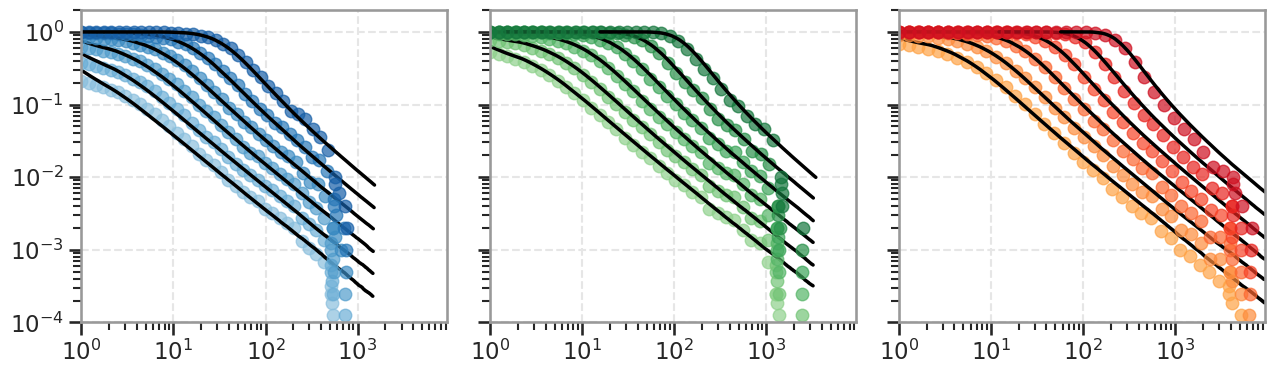

3b written (23s)


muN =  1.0: yKH88 k=5627, yFR1 k=16027, yFR2 k=28008


muN =  5.0: yKH88 k=1125, yFR1 k=3205, yFR2 k=5602
muN = 25.0: yKH88 k=225, yFR1 k=641, yFR2 k=1120


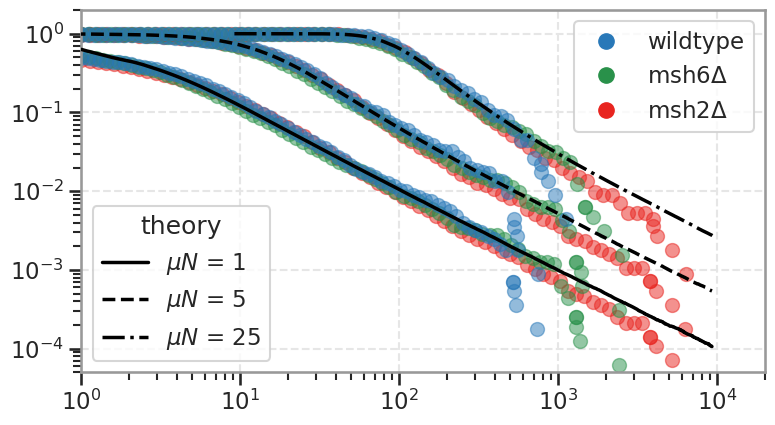

Done in 27s.


In [5]:
started = time.time()
use_paper_style()
OUTPUT_DIR.mkdir(exist_ok=True)
np.random.seed(SEED)

params = expt2.load_params()
strains = params["strains"]
best_mu = params["lap_best_mu"]
counts_pre, counts_post, reads_post, _ = expt2.load_counts(params)

for strain in strains:
    print(f"{strain}: {len(counts_pre[strain])} barcodes, "
          f"mu = {best_mu[strain]:.3e}, "
          f"mu*totalN = {best_mu[strain] * params['totalN'][strain]:.1f}, "
          f"alpha = {LAPLACE_ALPHA[strain]:.3f}")

plot_per_strain_ccdf(strains, counts_pre, counts_post, reads_post, params["CFU"],
                     params["totalN"], best_mu, LAPLACE_ALPHA)
print(f"3b written ({time.time() - started:.0f}s)")
plot_collapse(strains, counts_pre, counts_post, reads_post, params["CFU"],
              params["totalN"], best_mu, LAPLACE_ALPHA)
print(f"Done in {time.time() - started:.0f}s.")

In [6]:
sys.path.insert(0, str(ROOT))